<a href="https://colab.research.google.com/github/anfegomez2026/workshop3-tdsp-ventas/blob/main/Code/01_Data_Acquisition_and_Understanding/01_Data_Acquisition_and_Understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns, warnings
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

URL = "https://docs.google.com/spreadsheets/d/e/2PACX-1vSR7UD5-D1NVWyP8lgQ7R7QaN-FiZX8mkHI3piBLe7h34eYuqX7Kjt111lk1Y_jmQ/pub?gid=1926354761&single=true&output=csv"

# Postal Code como texto: si se lee como número se pierden los ceros a la izquierda
df_raw = pd.read_csv(URL, dtype={"Postal Code": str})
print(df_raw.shape)

(9994, 21)


In [2]:
df = df_raw.copy()

# Fechas en formato EE. UU. (mes/día/año), declarado explícitamente
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")

print("Rango de fechas:", df["Order Date"].min().date(), "→", df["Order Date"].max().date())
print("Filas duplicadas:", df.duplicated().sum())
print("Row ID único:", df["Row ID"].is_unique)
print("Pedidos:", df["Order ID"].nunique(), "| Clientes:", df["Customer ID"].nunique(),
      "| Productos:", df["Product ID"].nunique())
print("Envíos con fecha anterior al pedido:", (df["Ship Date"] < df["Order Date"]).sum())
print("Ventas <= 0:", (df["Sales"] <= 0).sum())
print("Descuentos fuera de [0,1]:", (~df["Discount"].between(0, 1)).sum())
print("Países:", df["Country"].unique())

q1, q3 = df["Sales"].quantile([.25, .75])
print("Líneas atípicas en Sales (regla IQR):", (df["Sales"] > q3 + 1.5 * (q3 - q1)).sum())

display(df[["Sales", "Quantity", "Discount", "Profit"]].describe().T.round(2))

Rango de fechas: 2014-01-03 → 2017-12-30
Filas duplicadas: 0
Row ID único: True
Pedidos: 5009 | Clientes: 793 | Productos: 1862
Envíos con fecha anterior al pedido: 0
Ventas <= 0: 0
Descuentos fuera de [0,1]: 0
Países: ['United States']
Líneas atípicas en Sales (regla IQR): 1167


,count,mean,std,min,25%,50%,75%,max
Sales,9994.0,229.86,623.25,0.44,17.28,54.49,209.94,22638.48
Quantity,9994.0,3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,9994.0,0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,9994.0,28.66,234.26,-6599.98,1.73,8.67,29.36,8399.98


In [3]:
# Agregación mensual (MS = inicio de mes)
ventas_mes = df.set_index("Order Date")["Sales"].resample("MS").sum().to_frame("Sales")
ventas_mes.index.name = "Month"

esperados = pd.date_range(ventas_mes.index.min(), ventas_mes.index.max(), freq="MS")
print("Meses en la serie:", len(ventas_mes), "|", ventas_mes.index.min().date(), "→", ventas_mes.index.max().date())
print("Meses faltantes:", len(esperados.difference(ventas_mes.index)))
print("Meses con ventas = 0:", (ventas_mes["Sales"] == 0).sum())

# Serie mensual por categoría (para insights)
ventas_cat = df.pivot_table(index=pd.Grouper(key="Order Date", freq="MS"),
                            columns="Category", values="Sales", aggfunc="sum")

ventas_mes.to_csv("ventas_mensuales.csv")
ventas_cat.to_csv("ventas_mensuales_categoria.csv")
display(ventas_mes.head(12).round(2))

Meses en la serie: 48 | 2014-01-01 → 2017-12-01
Meses faltantes: 0
Meses con ventas = 0: 0


,Sales
Month,
2014-01-01,14236.90
2014-02-01,4519.89
2014-03-01,55691.01
2014-04-01,28295.34
2014-05-01,23648.29
2014-06-01,34595.13
2014-07-01,33946.39
2014-08-01,27909.47
2014-09-01,81777.35


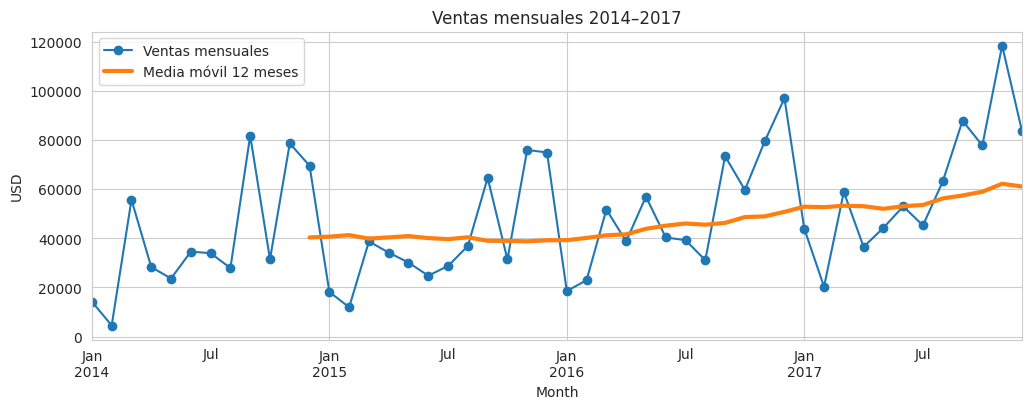

,Ventas,Crecimiento %
Month,,
2014,484247.0,NaN
2015,470533.0,-2.8
2016,609206.0,29.5
2017,733215.0,20.4


In [4]:
ax = ventas_mes["Sales"].plot(marker="o", label="Ventas mensuales")
ventas_mes["Sales"].rolling(12).mean().plot(ax=ax, lw=3, label="Media móvil 12 meses")
ax.set_title("Ventas mensuales 2014–2017"); ax.set_ylabel("USD"); ax.legend(); plt.show()

anual = ventas_mes["Sales"].groupby(ventas_mes.index.year).sum()
display(pd.DataFrame({"Ventas": anual.round(0), "Crecimiento %": (anual.pct_change() * 100).round(1)}))

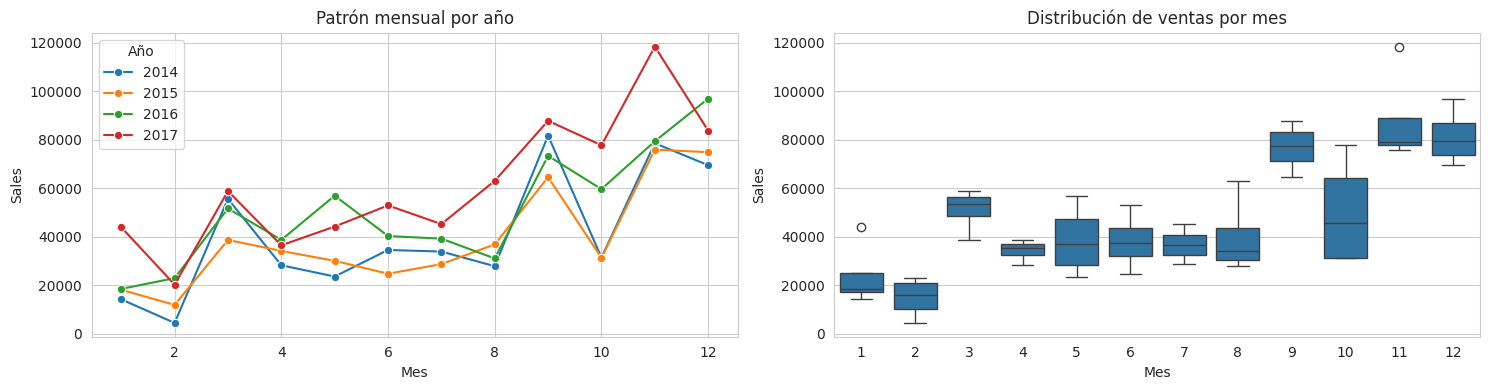

Índice estacional (1 = mes promedio):
 Mes
1     0.50
2     0.31
3     1.07
4     0.72
5     0.81
6     0.80
7     0.77
8     0.83
9     1.61
10    1.05
11    1.84
12    1.70
Name: Sales, dtype: float64


,Media,Amplitud
Año,,
2014,40354.0,77257.0
2015,39211.0,64021.0
2016,50767.0,78457.0
2017,61101.0,98147.0


In [5]:
tmp = ventas_mes.assign(Año=ventas_mes.index.year, Mes=ventas_mes.index.month)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.lineplot(data=tmp, x="Mes", y="Sales", hue="Año", palette="tab10", marker="o", ax=axes[0])
axes[0].set_title("Patrón mensual por año")
sns.boxplot(data=tmp, x="Mes", y="Sales", ax=axes[1])
axes[1].set_title("Distribución de ventas por mes")
plt.tight_layout(); plt.show()

indice_estacional = (tmp.groupby("Mes")["Sales"].mean() / tmp["Sales"].mean()).round(2)
print("Índice estacional (1 = mes promedio):\n", indice_estacional)

# ¿La amplitud estacional crece con el nivel? → indica comportamiento multiplicativo
display(tmp.groupby("Año")["Sales"].agg(Media="mean", Amplitud=lambda x: x.max() - x.min()).round(0))

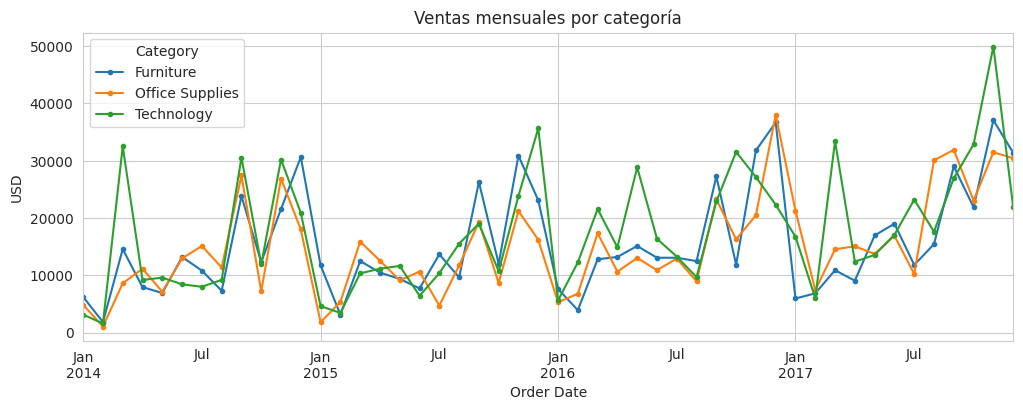

Participación % en ventas:
 Category
Furniture          32.3
Office Supplies    31.3
Technology         36.4
Name: Sales, dtype: float64


In [6]:
ventas_cat.plot(title="Ventas mensuales por categoría", marker=".")
plt.ylabel("USD"); plt.show()
print("Participación % en ventas:\n", (df.groupby("Category")["Sales"].sum() / df["Sales"].sum() * 100).round(1))

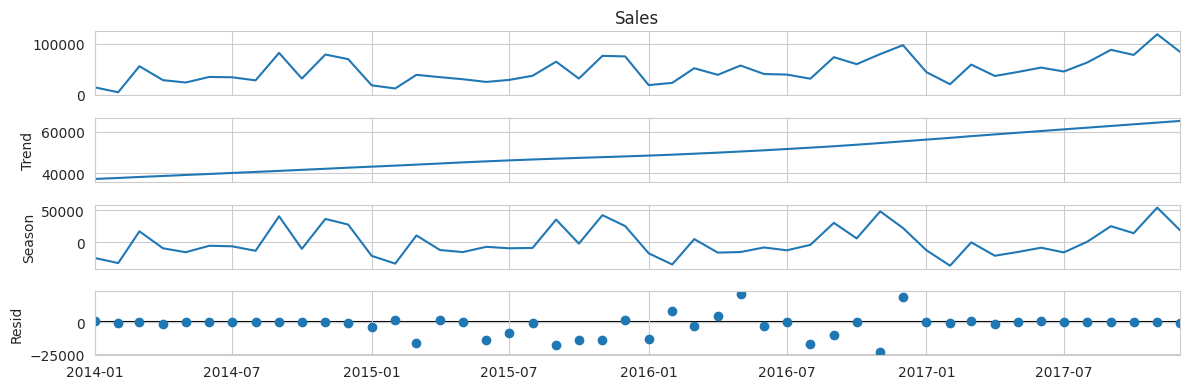

Fuerza de la tendencia: 0.53 | Fuerza de la estacionalidad: 0.86


In [7]:
stl = STL(ventas_mes["Sales"], period=12, robust=True).fit()
stl.plot(); plt.show()

T, S, R = stl.trend, stl.seasonal, stl.resid
fuerza_tendencia = max(0, 1 - R.var() / (T + R).var())
fuerza_estacional = max(0, 1 - R.var() / (S + R).var())
print(f"Fuerza de la tendencia: {fuerza_tendencia:.2f} | Fuerza de la estacionalidad: {fuerza_estacional:.2f}")

In [8]:
def pruebas(serie, nombre):
    s = serie.dropna()
    p_adf = adfuller(s, autolag="AIC")[1]           # H0: NO estacionaria
    p_kpss = kpss(s, regression="c", nlags="auto")[1]  # H0: SÍ estacionaria
    if p_adf < 0.05 and p_kpss > 0.05:   concl = "Estacionaria"
    elif p_adf >= 0.05 and p_kpss <= 0.05: concl = "No estacionaria"
    else:                                 concl = "Resultado mixto"
    return {"Serie": nombre, "n": len(s), "ADF p": round(p_adf, 4), "KPSS p": round(p_kpss, 4), "Conclusión": concl}

y = ventas_mes["Sales"]; ly = np.log(y)
resultados = pd.DataFrame([
    pruebas(y, "Original"),
    pruebas(ly, "Log"),
    pruebas(ly.diff(), "Log + diff(1)"),
    pruebas(ly.diff(12), "Log + diff estacional(12)"),
    pruebas(ly.diff(12).diff(), "Log + diff(12) + diff(1)"),
])
display(resultados)

,Serie,n,ADF p,KPSS p,Conclusión
0,Original,48,0.0002,0.0187,Resultado mixto
1,Log,48,0.0000,0.0100,Resultado mixto
2,Log + diff(1),47,0.0000,0.1000,Estacionaria
3,Log + diff estacional(12),36,0.0000,0.1000,Estacionaria
4,Log + diff(12) + diff(1),35,0.0000,0.1000,Estacionaria


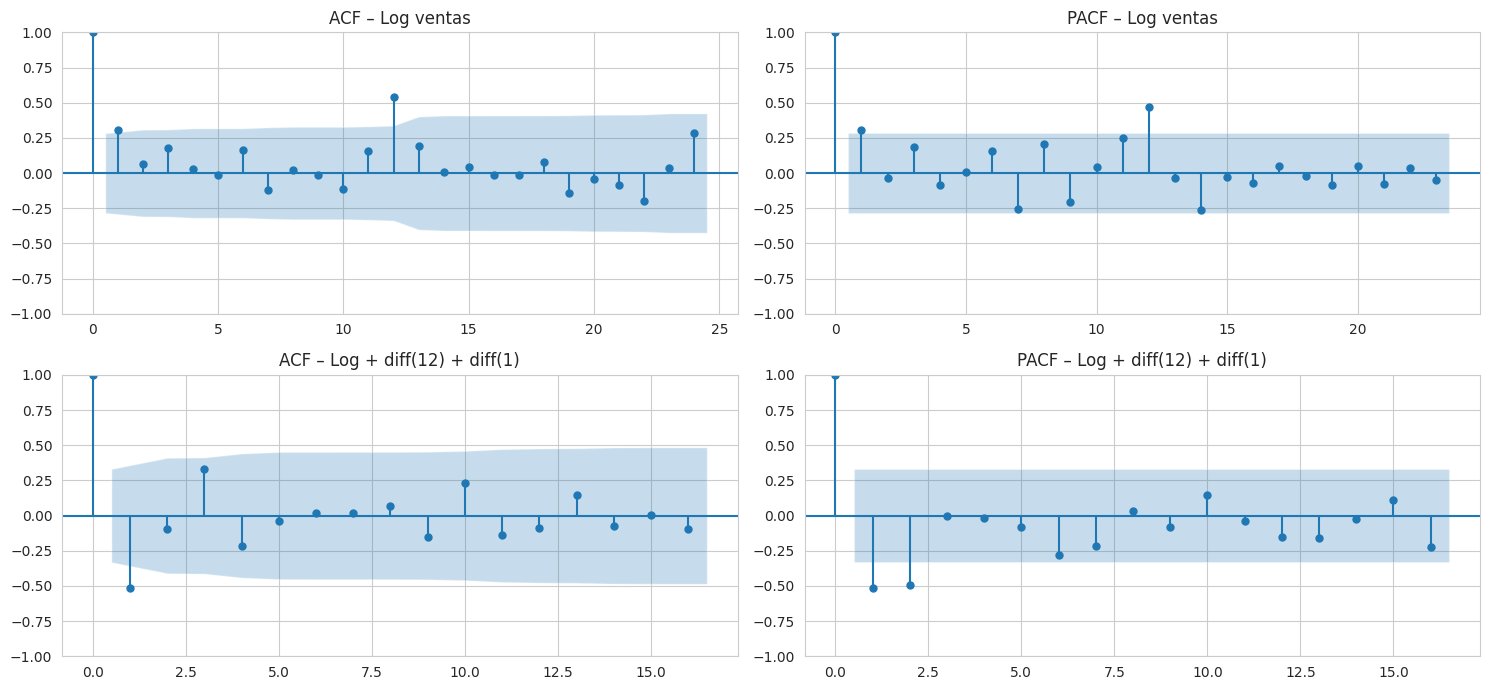

In [9]:
def max_lag_pacf(s): return min(24, len(s.dropna()) // 2 - 1)

s1 = ly.dropna()
s2 = ly.diff(12).diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(15, 7))
plot_acf(s1, lags=24, ax=axes[0, 0], title="ACF – Log ventas")
plot_pacf(s1, lags=max_lag_pacf(s1), ax=axes[0, 1], method="ywm", title="PACF – Log ventas")
plot_acf(s2, lags=max_lag_pacf(s2), ax=axes[1, 0], title="ACF – Log + diff(12) + diff(1)")
plot_pacf(s2, lags=max_lag_pacf(s2), ax=axes[1, 1], method="ywm", title="PACF – Log + diff(12) + diff(1)")
plt.tight_layout(); plt.show()

In [10]:
z = (R - R.mean()) / R.std()
print("Meses atípicos (|z| > 2 en el residuo STL):")
display(ventas_mes.assign(z_residuo=z.round(2))[z.abs() > 2].round(2))

from google.colab import files
for f in ["ventas_mensuales.csv", "ventas_mensuales_categoria.csv"]:
    files.download(f)   # súbelos a Sample_Data/Processed/ en GitHub

Meses atípicos (|z| > 2 en el residuo STL):


,Sales,z_residuo
Month,,
2016-05-01,56987.73,2.91
2016-11-01,79411.97,-2.62
2016-12-01,96999.04,2.61


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
df_raw.to_csv("ventas_raw.csv", index=False)

from google.colab import files
files.download("ventas_raw.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>